# NovaCart business analysis

Descriptive analysis of 24 months of trading for the fictional NovaCart e-commerce store.
All numbers come from the PostgreSQL analytical layer built in Milestone 2 - this notebook
only *reads and presents* them, so it cannot disagree with SQL, the report script or BI.

**Revenue definition.** Revenue is *recognised net merchandise revenue*: `items_subtotal -
discount_amount` for orders with status `completed`. Refunded and cancelled orders are
excluded, and shipping and VAT are never part of revenue.

**How to run.** Load and build the warehouse first:

```bash
docker compose up -d
python scripts/generate_data.py && python scripts/load_raw.py
python scripts/build_analytics_layer.py
```

In [1]:
import pandas as pd

from novacart.analytics.common import load_analysis_inputs
from novacart.analytics.kpis import kpi_display
from novacart.analytics.plots import render_all_figures
from novacart.analytics.report import analyse

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

## 1. Load the published analytical layer

The loader reads only published views: order and line facts, the customer, product and
category marts, and the daily/monthly revenue marts.

In [2]:
inputs = load_analysis_inputs()
print(f"orders        : {len(inputs.orders):>9,}")
print(f"order lines   : {len(inputs.order_lines):>9,}")
print(f"customers     : {len(inputs.customers):>9,}")
print(f"products      : {len(inputs.products):>9,}")
print(f"daily periods : {len(inputs.daily):>9,}")
print(f"monthly periods: {len(inputs.monthly):>8,}")

orders        :    84,263
order lines   :   207,374
customers     :    15,000
products      :     1,200
daily periods :       730
monthly periods:       24


## 2. Business KPI snapshot

One canonical KPI table for the whole window. `repeat_customer_rate` comes from the customer
mart, so the notebook, SQL and any dashboard quote the same definition.

In [3]:
analysis = analyse(inputs)
kpi_display(analysis.kpis)

,metric,value
0,Analysis window,2024-10-01 to 2026-09-30
1,Days in window,730
2,Total revenue,EUR 14.86m
3,Total orders,"78,896"
4,Total units,"250,532"
5,Purchasing customers,"7,622"
6,Registered customers,"15,000"
7,Average order value,EUR 188.37
8,Average units per order,3.18
9,Revenue per purchasing customer,EUR 1.95k


### Revenue and order metrics in full

`revenue_per_customer` uses purchasing customers; `revenue_per_registered_customer` uses all
15,000 registered customers, including the ones who never bought.

In [4]:
revenue_summary = analysis.revenue.iloc[0]
pd.DataFrame(
    {
        "metric": [
            "total net revenue",
            "recognised orders",
            "purchasing customers",
            "repeat customers",
            "one-time customers",
            "average order value",
            "average units per order",
            "orders per customer",
            "revenue per customer",
        ],
        "value": [
            f"EUR {revenue_summary['total_revenue']:,.2f}",
            f"{revenue_summary['total_orders']:,}",
            f"{revenue_summary['unique_customers']:,}",
            f"{revenue_summary['repeat_customers']:,}",
            f"{revenue_summary['one_time_customers']:,}",
            f"EUR {revenue_summary['average_order_value']:,.2f}",
            f"{revenue_summary['average_units_per_order']:.2f}",
            f"{revenue_summary['orders_per_customer']:.2f}",
            f"EUR {revenue_summary['revenue_per_customer']:,.2f}",
        ],
    }
)

,metric,value
0,total net revenue,"EUR 14,861,510.32"
1,recognised orders,"78,896"
2,purchasing customers,"7,622"
3,repeat customers,"4,331"
4,one-time customers,"3,291"
5,average order value,EUR 188.37
6,average units per order,3.18
7,orders per customer,10.35
8,revenue per customer,"EUR 1,949.82"


## 3. Monthly trend and month-over-month change

Monthly metrics sit on a complete calendar, so a month with no recognised revenue still
appears and month-over-month comparisons always look at the immediately preceding month.

In [5]:
monthly_view = analysis.monthly[
    [
        "year_month",
        "orders_recognised",
        "purchasing_customers",
        "units",
        "revenue",
        "average_order_value",
        "revenue_mom_pct",
        "orders_recognised_mom_pct",
        "average_order_value_mom_pct",
    ]
].rename(
    columns={
        "orders_recognised": "orders",
        "purchasing_customers": "customers",
        "average_order_value": "aov",
        "revenue_mom_pct": "revenue_mom",
        "orders_recognised_mom_pct": "orders_mom",
        "average_order_value_mom_pct": "aov_mom",
    }
)
monthly_view.tail(12).style.format(
    {
        "revenue": "EUR {:,.0f}",
        "aov": "EUR {:,.2f}",
        "revenue_mom": "{:.1%}",
        "orders_mom": "{:.1%}",
        "aov_mom": "{:.1%}",
    }
)

,year_month,orders,customers,units,revenue,aov,revenue_mom,orders_mom,aov_mom
12,2025-10,3388,1699,10606,"EUR 632,880",EUR 186.80,21.0%,18.3%,2.3%
13,2025-11,5341,2132,17223,"EUR 1,061,210",EUR 198.69,67.7%,57.6%,6.4%
14,2025-12,5250,2196,16839,"EUR 982,923",EUR 187.22,-7.4%,-1.7%,-5.8%
15,2026-01,3057,1679,9824,"EUR 573,531",EUR 187.61,-41.6%,-41.8%,0.2%
16,2026-02,3026,1715,9563,"EUR 561,336",EUR 185.50,-2.1%,-1.0%,-1.1%
17,2026-03,4337,2028,13901,"EUR 825,310",EUR 190.30,47.0%,43.3%,2.6%
18,2026-04,3958,1986,12545,"EUR 753,641",EUR 190.41,-8.7%,-8.7%,0.1%
19,2026-05,3881,2017,12379,"EUR 739,180",EUR 190.46,-1.9%,-1.9%,0.0%
20,2026-06,5386,2412,17258,"EUR 1,025,458",EUR 190.39,38.7%,38.8%,-0.0%
21,2026-07,4529,2269,14409,"EUR 872,166",EUR 192.57,-14.9%,-15.9%,1.1%


## 4. Daily activity and rolling revenue

Rolling windows are trailing sums that include the current day, matching the SQL mart exactly
(verified by `tests/test_analytics_integration.py`).

In [6]:
daily_view = analysis.daily[
    [
        "order_date",
        "day_name",
        "orders_recognised",
        "purchasing_customers",
        "units",
        "revenue",
        "revenue_rolling_7d",
        "revenue_rolling_30d",
    ]
].tail(14)
daily_view.style.format(
    {
        "revenue": "EUR {:,.0f}",
        "revenue_rolling_7d": "EUR {:,.0f}",
        "revenue_rolling_30d": "EUR {:,.0f}",
    }
)

,order_date,day_name,orders_recognised,purchasing_customers,units,revenue,revenue_rolling_7d,revenue_rolling_30d
716,2026-09-17 00:00:00,Thursday,190,183,583,"EUR 32,736","EUR 221,564","EUR 925,443"
717,2026-09-18 00:00:00,Friday,163,156,516,"EUR 30,440","EUR 220,279","EUR 924,411"
718,2026-09-19 00:00:00,Saturday,148,146,415,"EUR 26,173","EUR 216,519","EUR 922,655"
719,2026-09-20 00:00:00,Sunday,148,145,447,"EUR 25,337","EUR 213,283","EUR 912,939"
720,2026-09-21 00:00:00,Monday,164,160,487,"EUR 26,984","EUR 205,256","EUR 910,653"
721,2026-09-22 00:00:00,Tuesday,179,174,569,"EUR 36,902","EUR 211,792","EUR 920,948"
722,2026-09-23 00:00:00,Wednesday,152,148,465,"EUR 27,166","EUR 205,738","EUR 916,909"
723,2026-09-24 00:00:00,Thursday,178,173,597,"EUR 36,444","EUR 209,446","EUR 923,776"
724,2026-09-25 00:00:00,Friday,186,178,592,"EUR 31,861","EUR 210,868","EUR 930,674"
725,2026-09-26 00:00:00,Saturday,150,146,497,"EUR 30,736","EUR 215,430","EUR 925,759"


## 5. Business figures

The seven required figures are written to `outputs/figures/` with deterministic filenames, so
they can be regenerated by the script `python scripts/build_business_analysis.py`.

In [7]:
from IPython.display import Image, display

figures = render_all_figures(
    monthly=analysis.monthly,
    categories=analysis.categories,
    products=analysis.products,
    customers=inputs.customers,
    countries=analysis.countries,
)
for name in sorted(figures):
    print(f"{name:<32} {figures[name].name}")

customer_revenue_distribution    customer_revenue_distribution.png
monthly_aov                      monthly_aov_trend.png
monthly_orders                   monthly_orders_trend.png
monthly_revenue                  monthly_revenue_trend.png
revenue_by_category              revenue_by_category.png
revenue_by_country               revenue_by_country.png
top_products_by_revenue          top10_products_by_revenue.png


**Is revenue growing?** Monthly net revenue with the seasonal peaks visible.

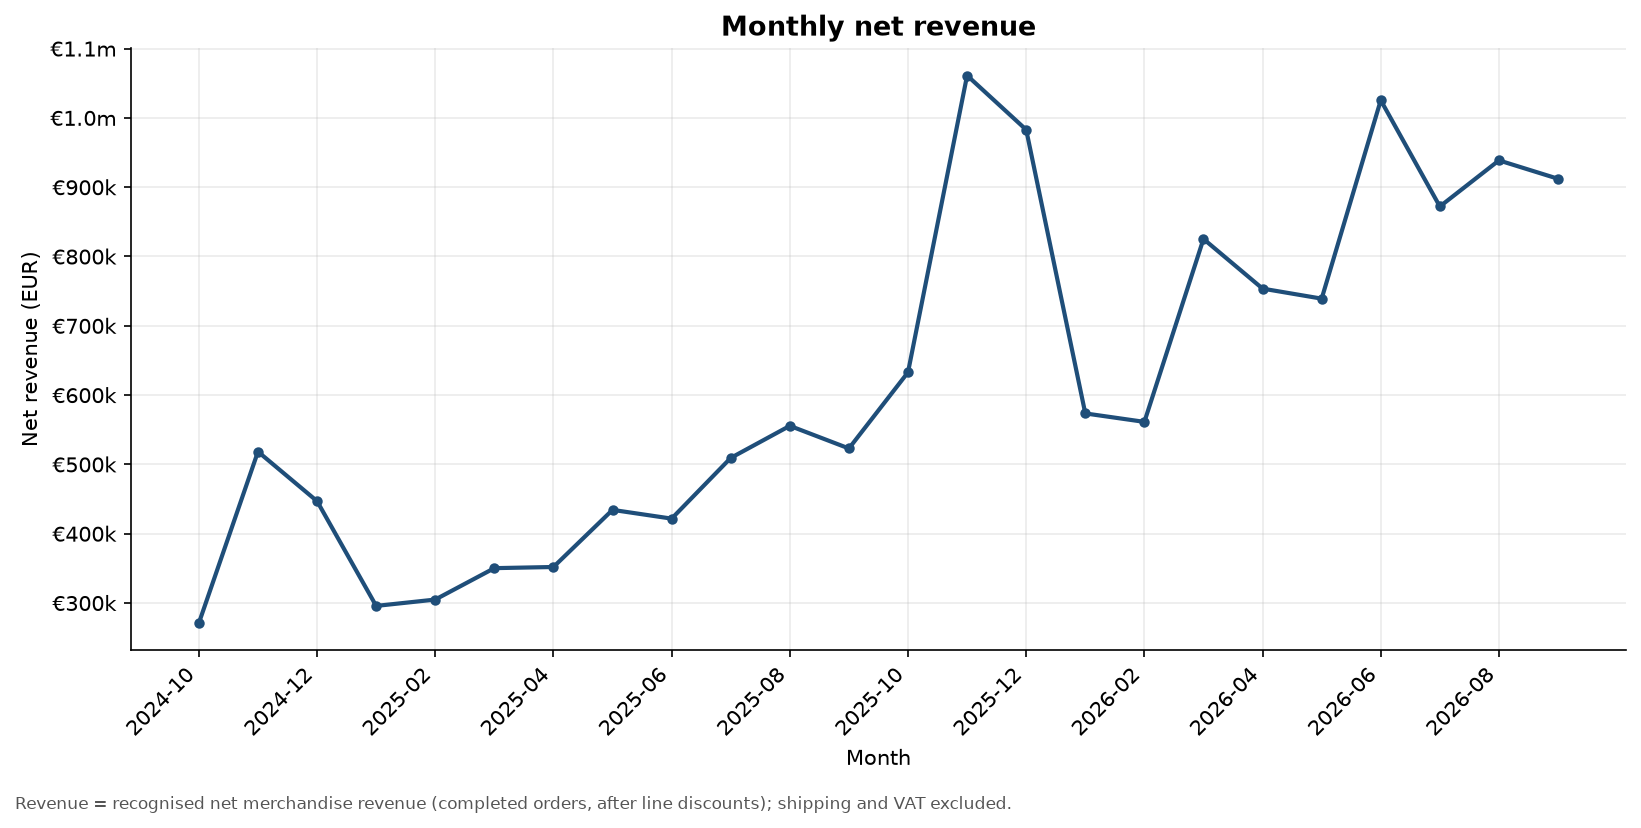

In [8]:
display(Image(filename=str(figures["monthly_revenue"])))

**Is order volume following revenue?** Completed orders per month.

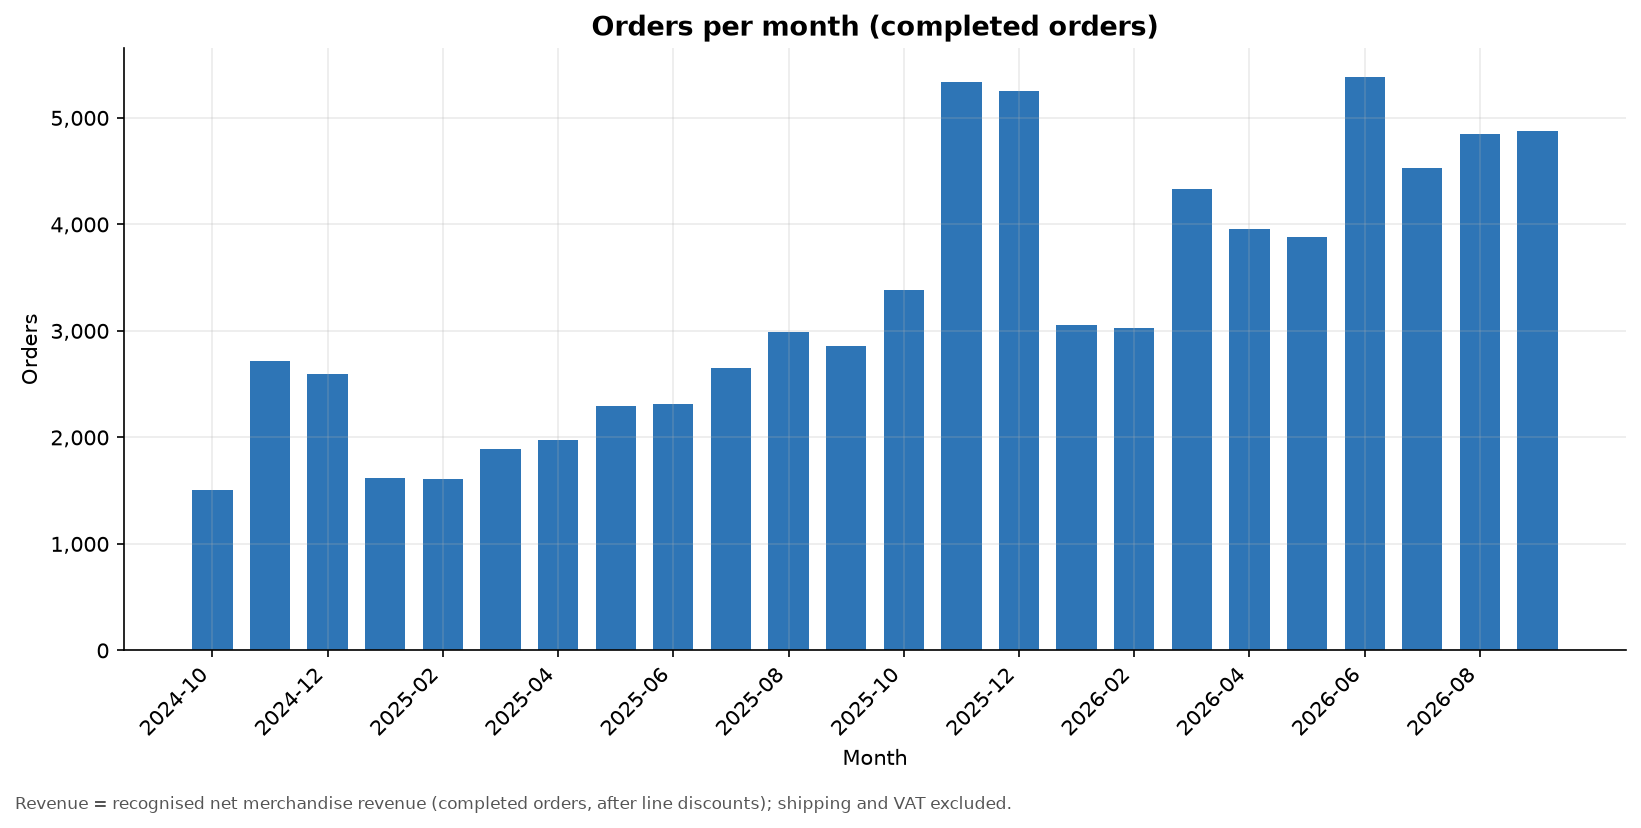

In [9]:
display(Image(filename=str(figures["monthly_orders"])))

**Are customers spending more per order?** Average order value per month.

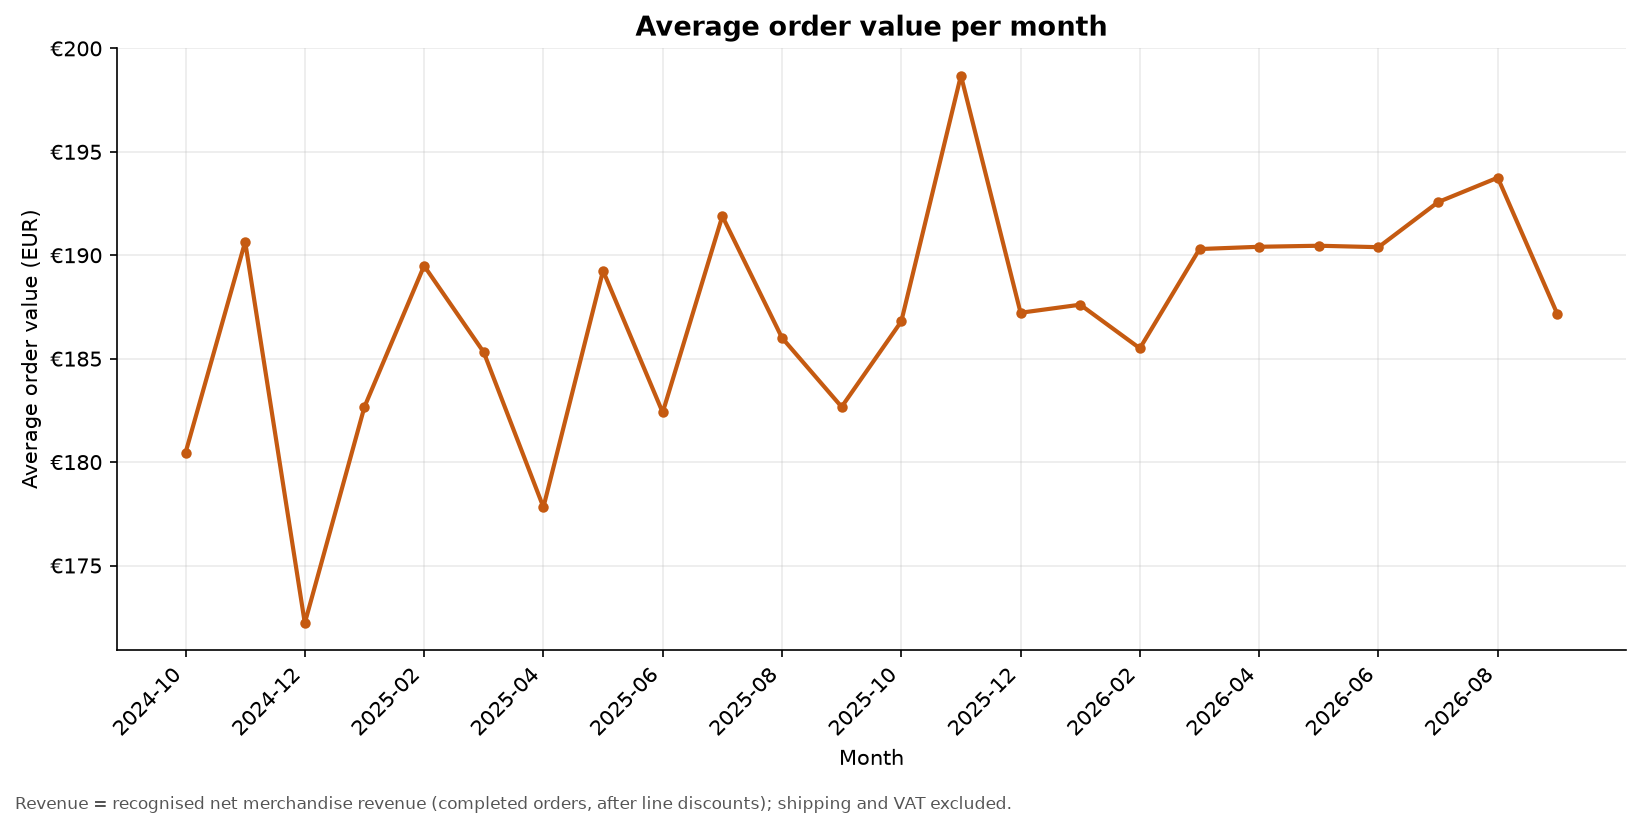

In [10]:
display(Image(filename=str(figures["monthly_aov"])))

**Which categories drive revenue?** Revenue by category over the 24 months.

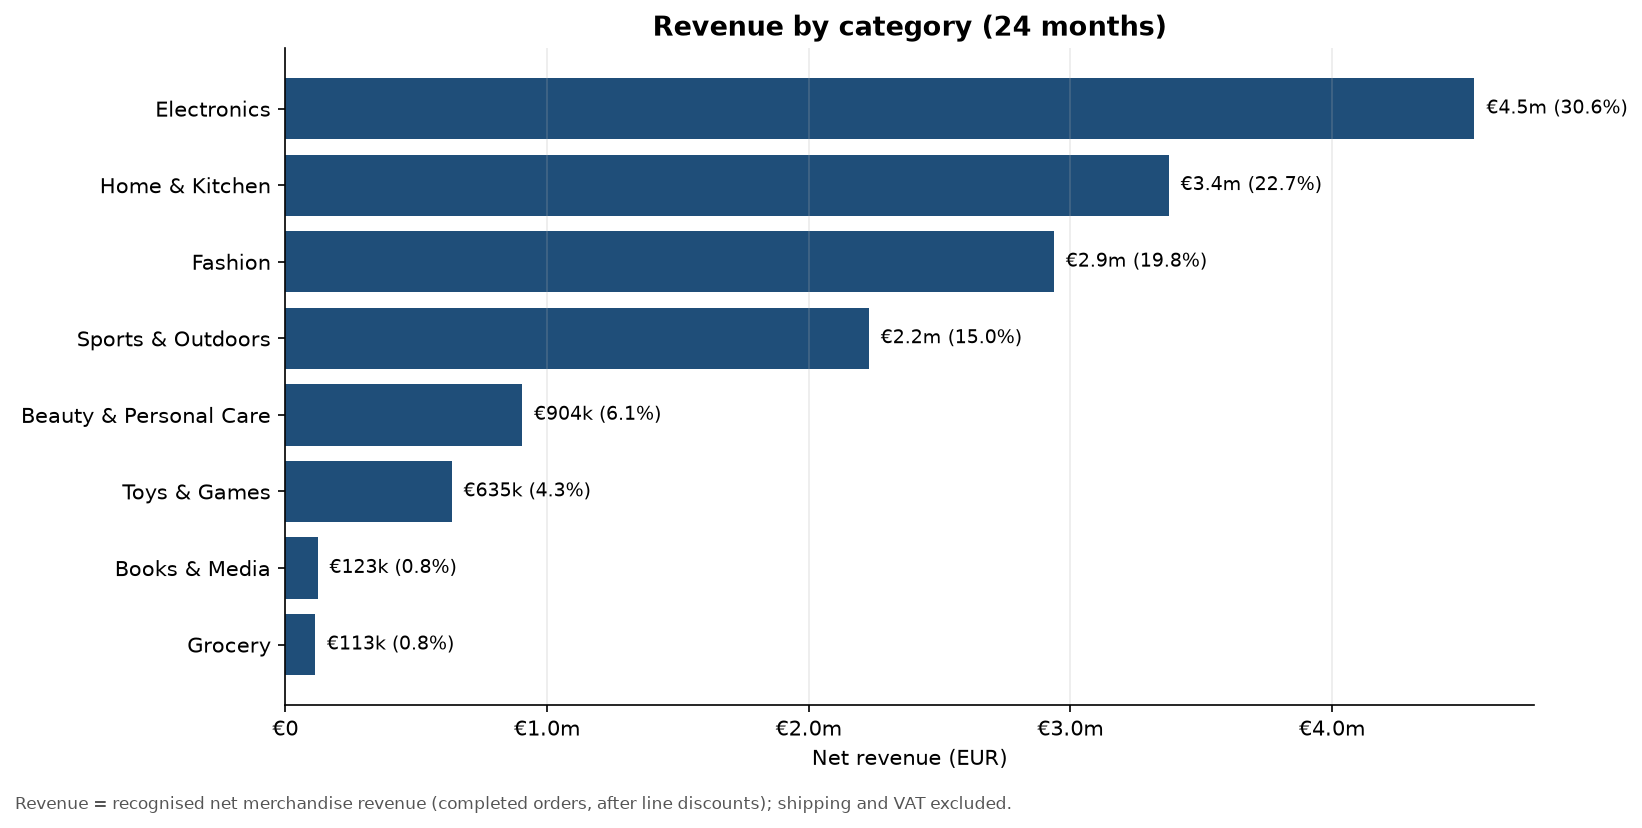

In [11]:
display(Image(filename=str(figures["revenue_by_category"])))

**Which individual products earn the most?** Top 10 products by net revenue.

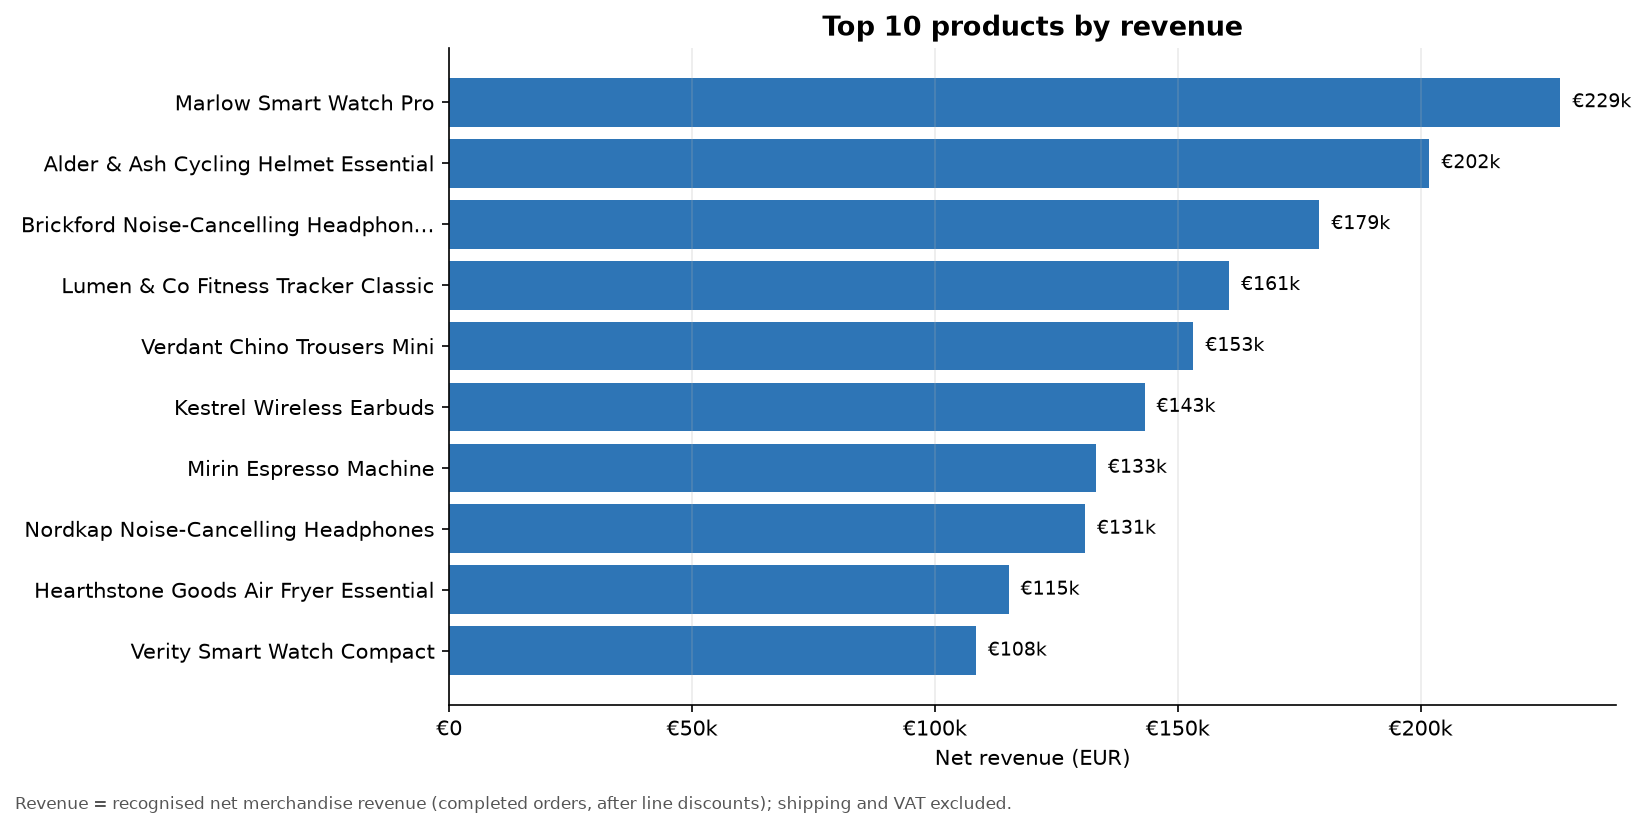

In [12]:
display(Image(filename=str(figures["top_products_by_revenue"])))

**How concentrated is revenue across customers?** Distribution of customer revenue and the
share of revenue by customer decile.

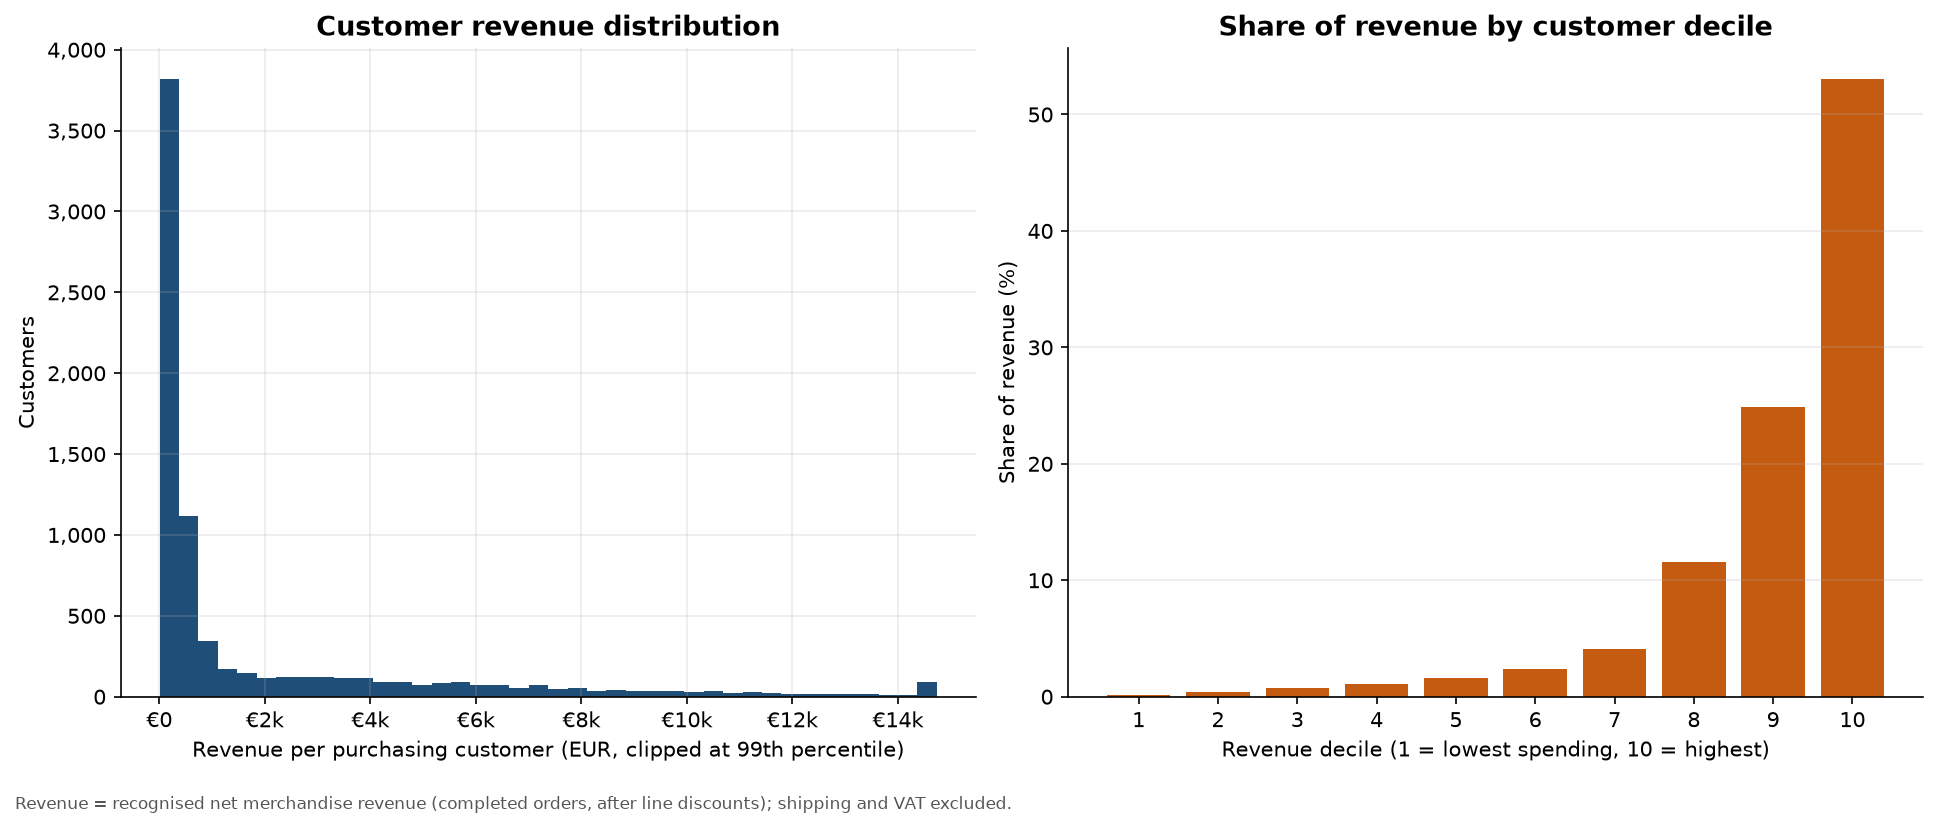

In [13]:
display(Image(filename=str(figures["customer_revenue_distribution"])))

**Which markets contribute most?** Revenue by country (top 12).

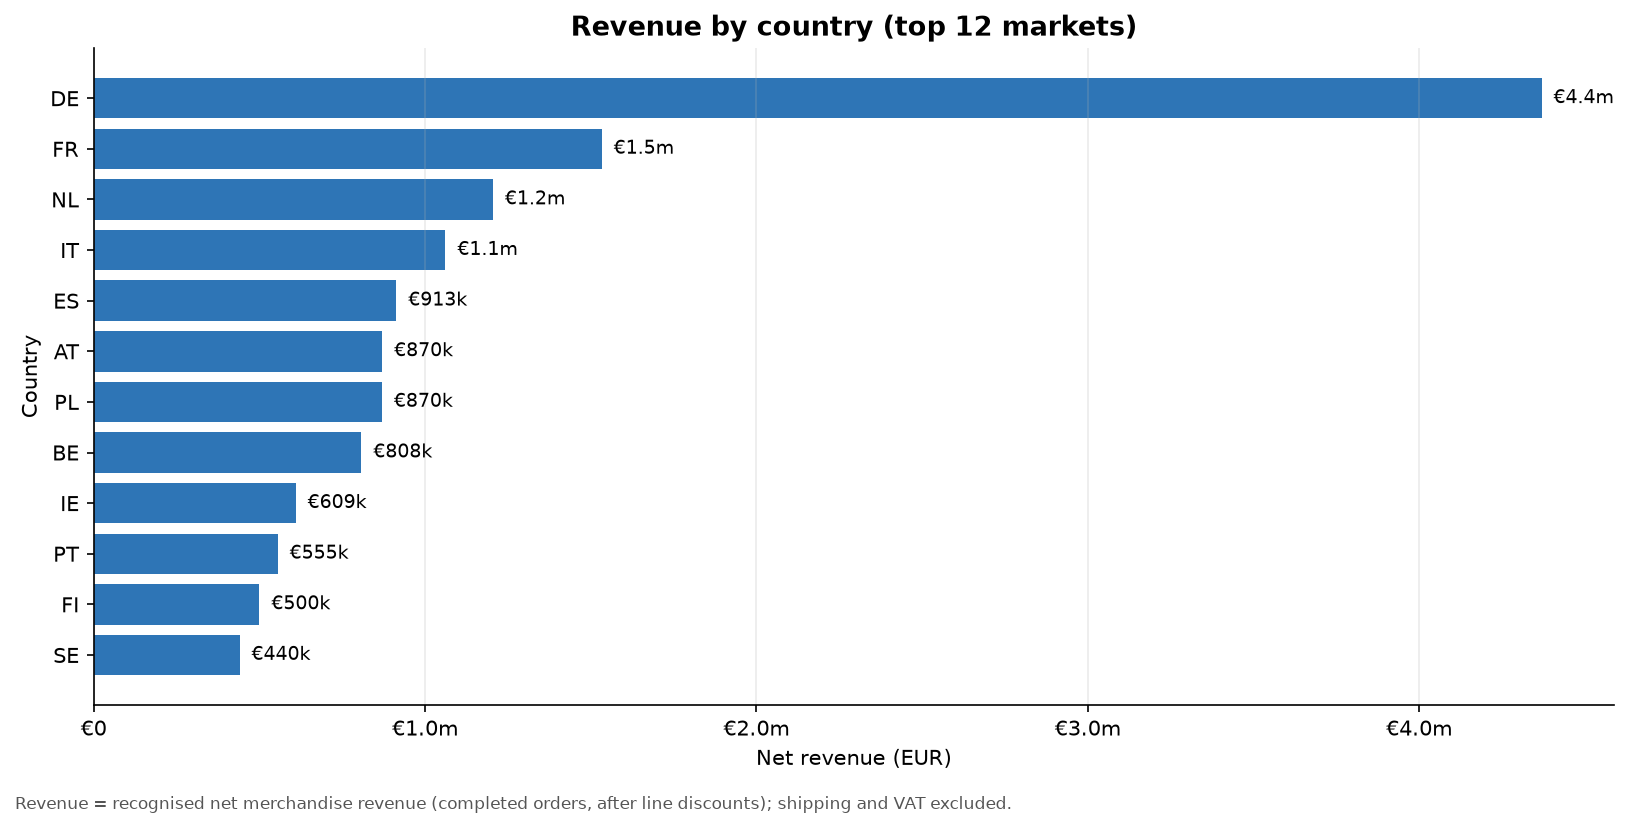

In [14]:
display(Image(filename=str(figures["revenue_by_country"])))

## 6. Product performance

Products are ranked on recognised revenue and recognised units. Both metrics are shown, so a
high-volume component is never confused with a high-value product.

In [15]:
analysis.categories.style.format(
    {
        "revenue": "EUR {:,.0f}",
        "average_selling_price": "EUR {:,.2f}",
        "revenue_share_pct": "{:.1f}%",
    }
)

,category,revenue,units,orders,customers,average_selling_price,revenue_share_pct
0,Electronics,"EUR 4,544,230",29928,18676,3772,EUR 151.84,30.6%
1,Home & Kitchen,"EUR 3,375,618",51414,29416,4614,EUR 65.66,22.7%
2,Fashion,"EUR 2,936,855",62047,34259,5112,EUR 47.33,19.8%
3,Sports & Outdoors,"EUR 2,229,396",30719,19125,3821,EUR 72.57,15.0%
4,Beauty & Personal Care,"EUR 904,416",40482,24270,4229,EUR 22.34,6.1%
5,Toys & Games,"EUR 635,160",19907,13130,3029,EUR 31.91,4.3%
6,Books & Media,"EUR 122,754",7061,5059,1720,EUR 17.38,0.8%
7,Grocery,"EUR 113,081",8974,6375,1985,EUR 12.60,0.8%


**Top 10 by revenue versus top 10 by units** - the two lists rarely overlap completely, which
is exactly why both are reported.

In [16]:
columns = ["product_id", "product_name", "category", "revenue", "units", "orders", "customers"]
analysis.top_products_revenue[columns].style.format({"revenue": "EUR {:,.0f}"})

,product_id,product_name,category,revenue,units,orders,customers
0,PRD-01176,Marlow Smart Watch Pro,Electronics,"EUR 228,769",691,542,455
1,PRD-00579,Alder & Ash Cycling Helmet Essential,Sports & Outdoors,"EUR 201,805",944,742,590
2,PRD-00568,Brickford Noise-Cancelling Headphones Classic,Electronics,"EUR 179,145",1471,1153,806
3,PRD-01148,Lumen & Co Fitness Tracker Classic,Electronics,"EUR 160,572",1136,877,675
4,PRD-00531,Verdant Chino Trousers Mini,Fashion,"EUR 153,216",2086,1608,1106
5,PRD-00027,Kestrel Wireless Earbuds,Electronics,"EUR 143,153",507,391,345
6,PRD-00143,Mirin Espresso Machine,Home & Kitchen,"EUR 133,157",1710,1335,942
7,PRD-00058,Nordkap Noise-Cancelling Headphones,Electronics,"EUR 130,896",838,641,522
8,PRD-01083,Hearthstone Goods Air Fryer Essential,Home & Kitchen,"EUR 115,171",849,666,544
9,PRD-00786,Verity Smart Watch Compact,Electronics,"EUR 108,431",444,325,286


In [17]:
analysis.top_products_units[columns].style.format({"revenue": "EUR {:,.0f}"})

,product_id,product_name,category,revenue,units,orders,customers
0,PRD-00475,Silverleaf Moisturiser Essential,Beauty & Personal Care,"EUR 91,767",6286,4897,2045
1,PRD-00060,Corvus Sneakers Premium,Fashion,"EUR 65,468",3362,2625,1488
2,PRD-00577,Alder & Ash Card Game,Toys & Games,"EUR 90,632",2663,2070,1133
3,PRD-00531,Verdant Chino Trousers Mini,Fashion,"EUR 153,216",2086,1608,1106
4,PRD-00143,Mirin Espresso Machine,Home & Kitchen,"EUR 133,157",1710,1335,942
5,PRD-00568,Brickford Noise-Cancelling Headphones Classic,Electronics,"EUR 179,145",1471,1153,806
6,PRD-00404,Corvus Denim Jacket,Fashion,"EUR 61,411",1268,987,757
7,PRD-01059,Pinewood Action Figure,Toys & Games,"EUR 20,873",1266,965,670
8,PRD-00631,Marlow Air Fryer,Home & Kitchen,"EUR 66,363",1146,862,652
9,PRD-01148,Lumen & Co Fitness Tracker Classic,Electronics,"EUR 160,572",1136,877,675


### Products with declining recent performance

Rule: compare the most recent 90 days with the 90 days before that. A product is flagged when
it sold at least 10 units in the prior window **and** recognised units fell by 30% or more.
`as_of` here is the last order date in the data, never today's date.

In [18]:
declining = analysis.declining_products
print(f"products compared      : {len(declining):,}")
print(f"flagged as declining   : {int(declining['is_declining'].sum()):,}")
declining.loc[declining["is_declining"], [
    "product_id", "product_name", "category", "prior_units", "recent_units",
    "units_change_pct", "revenue_change_pct",
]].head(10).style.format({"units_change_pct": "{:.1%}", "revenue_change_pct": "{:.1%}"})

products compared      : 1,118
flagged as declining   : 162


,product_id,product_name,category,prior_units,recent_units,units_change_pct,revenue_change_pct
0,PRD-00171,Mirin Nut Mix,Grocery,26,3,-88.5%,-87.9%
1,PRD-00133,Pinewood Fitness Tracker Premium,Electronics,22,6,-72.7%,-70.7%
2,PRD-00081,Wildacre Moisturiser,Beauty & Personal Care,27,8,-70.4%,-68.8%
3,PRD-00659,Nordkap Rain Jacket,Fashion,26,9,-65.4%,-63.5%
4,PRD-00319,Wildacre Building Blocks Set,Toys & Games,20,7,-65.0%,-65.0%
5,PRD-01065,Pinewood Protein Bars Premium,Grocery,17,6,-64.7%,-63.9%
6,PRD-00180,Cassia Biography Essential,Books & Media,44,16,-63.6%,-62.2%
7,PRD-00778,Verity Cookbook Pro,Books & Media,19,7,-63.2%,-63.8%
8,PRD-01132,Nomad Kits Foam Roller Pro,Sports & Outdoors,40,15,-62.5%,-61.1%
9,PRD-00514,Palladium Wireless Earbuds Studio,Electronics,20,8,-60.0%,-61.0%


## 7. Customer performance

Country performance distinguishes registered from purchasing customers, because a large
registered base with few buyers is a different business problem from a small buying market.

In [19]:
analysis.countries.style.format(
    {
        "revenue": "EUR {:,.0f}",
        "average_customer_revenue": "EUR {:,.0f}",
        "revenue_share_pct": "{:.1f}%",
    }
)

,country_code,registered_customers,purchasing_customers,orders,revenue,average_customer_revenue,revenue_share_pct
0,DE,4572,2263,23329,"EUR 4,369,196","EUR 1,931",29.4%
1,FR,1524,775,8153,"EUR 1,532,944","EUR 1,978",10.3%
2,NL,1183,612,6447,"EUR 1,204,722","EUR 1,968",8.1%
3,IT,1046,556,5557,"EUR 1,061,355","EUR 1,909",7.1%
4,ES,1069,551,4909,"EUR 913,054","EUR 1,657",6.1%
5,AT,886,439,4567,"EUR 870,331","EUR 1,983",5.9%
6,PL,754,409,4530,"EUR 869,663","EUR 2,126",5.9%
7,BE,770,387,4341,"EUR 807,577","EUR 2,087",5.4%
8,IE,573,291,3274,"EUR 609,225","EUR 2,094",4.1%
9,PT,584,300,2877,"EUR 554,992","EUR 1,850",3.7%


**Repeat versus one-time customers.** Revenue share, not just customer count, is the number
that matters for retention decisions.

In [20]:
analysis.segments.style.format(
    {
        "revenue": "EUR {:,.0f}",
        "average_customer_revenue": "EUR {:,.0f}",
        "average_orders_per_customer": "{:.2f}",
        "revenue_share_pct": "{:.1f}%",
    }
)

,segment,customers,orders,revenue,average_customer_revenue,average_orders_per_customer,revenue_share_pct
0,never_purchased,7378,0,EUR 0,EUR 0,0.00,0.0%
1,one_time,3291,3291,"EUR 620,760",EUR 189,1.00,4.2%
2,repeat,4331,75605,"EUR 14,240,751","EUR 3,288",17.46,95.8%


**How concentrated is revenue?** Deciles of purchasing customers, plus the concentration
summary. Concentration is reported as a measured fact; no "top customer" claim is made
without the underlying revenue metric.

In [21]:
display(analysis.concentration.T.rename(columns={0: "value"}))

,value
purchasing_customers,7.622000e+03
total_revenue,1.486151e+07
top_1pct_revenue_share_pct,9.175100e+00
top_10pct_revenue_share_pct,5.304730e+01
bottom_50pct_revenue_share_pct,4.034300e+00


In [22]:
analysis.top_customers[[
    "customer_id", "country_code", "acquisition_channel", "total_orders", "total_revenue",
    "average_order_value", "revenue_share_pct",
]].style.format(
    {
        "total_revenue": "EUR {:,.0f}",
        "average_order_value": "EUR {:,.2f}",
        "revenue_share_pct": "{:.2f}%",
    }
)

,customer_id,country_code,acquisition_channel,total_orders,total_revenue,average_order_value,revenue_share_pct
0,CUST-006840,DE,paid_social,80,"EUR 27,957",EUR 349.47,0.19%
1,CUST-003184,IT,referral,103,"EUR 27,174",EUR 263.83,0.18%
2,CUST-004175,NL,email,109,"EUR 26,322",EUR 241.49,0.18%
3,CUST-008612,PL,referral,92,"EUR 25,634",EUR 278.63,0.17%
4,CUST-002664,SE,organic_search,127,"EUR 24,640",EUR 194.02,0.17%
5,CUST-005205,FR,paid_social,124,"EUR 23,666",EUR 190.86,0.16%
6,CUST-007765,DE,paid_search,130,"EUR 22,823",EUR 175.56,0.15%
7,CUST-001831,ES,referral,72,"EUR 22,261",EUR 309.18,0.15%
8,CUST-010978,NL,organic_search,88,"EUR 22,257",EUR 252.92,0.15%
9,CUST-007082,SE,paid_social,69,"EUR 21,781",EUR 315.66,0.15%


## 8. Definitions and limitations

- **Revenue**: recognised net merchandise revenue (`items_subtotal - discount_amount` for
  completed orders). Shipping and VAT excluded; refunds and cancellations excluded.
- **Average order value**: revenue / recognised orders.
- **Rolling revenue**: trailing window including the current day, on a complete daily
  calendar (7-day and 30-day).
- **Repeat customer**: at least two recognised orders; repeat customer rate is repeat
  customers / purchasing customers.
- **Product ranking**: recognised revenue, ties broken by product id; unit ranking is shown
  separately because the two lists differ.
- **Declining product**: prior-window units >= 10 and unit change <= -30% across two adjacent
  90-day windows ending on the last order date.

Limitations: this is descriptive analysis of synthetic data. Nothing here is causal, no
significance testing has been applied, and campaign effects, RFM segments and cohort
retention are deliberately left to later milestones.